# SHAKENBAYEV ML MIDTERM PROJECT

In [1]:
import sys, sklearn, pandas as pd, numpy as np

SEED = 3246

print(sys.version)
print("sklearn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

train = pd.read_csv("data/train.csv")
test = pd.read_csv("data/test.csv")
print(train.shape, test.shape)

3.13.9 (tags/v3.13.9:8183fa5, Oct 14 2025, 14:09:13) [MSC v.1944 64 bit (AMD64)]
sklearn 1.7.2 | pandas 2.3.3 | numpy 2.3.4
(32940, 22) (8236, 20)


# Stage 1 · Frame the problem 

In [2]:
print("Колонки только в train:", set(train.columns) - set(test.columns))
print("Колонки только в test: ", set(test.columns) - set(train.columns))
print()
print(train.columns.tolist())

Колонки только в train: {'y', 'duration'}
Колонки только в test:  set()

['id', 'age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


## Stage 1 · Framing the problem

In this project I predict whether a client of a Portuguese bank will say yes to a term deposit offer made by phone.The model is used before any call is made: it gives a score to every client on a list.The call centre can phone only 10 % of the clients in one campaign wave,so I do not need a yes or no answer for every client.I need a good order of the clients,so that the top 10 % contain as many future yes clients as possible.

Because of this,accuracy is not a good metric.Only about 11 % of the clients say yes,so a classifier that always answers no would get about 89 % accuracy and would find nobody.I will compare models with ROC-AUC and average precision,because both depend only on the ranking of the clients and I will compute them for every fold and look at the mean and the standard deviation.For the final business result I will report precision and recall in the top 10 % and the lift over calling clients at random.

The file train.csv has two columns that test.csv does not have.The first one is y,which is the answer that I predict and the instructor keeps it hidden to score the model.The second one is duration,the length of the call in seconds.Duration is known only after the call has happened and it is strongly connected with the answer,because a long conversation usually means that the client is interested.Before the call this information does not exist,so a model trained with it would look very good in cross-validation but could not be used in real life and it could not even run on test.csv. This is target leakage.So I can use only information that is known before the call.I remove duration from the features and I also remove id,because it is only a row number and not a property of the client.

# Stage 2 · Understand the data

In [3]:
y = (train["y"] == "yes").astype(int)
X = train.drop(columns=["y", "duration", "id"])

print("Признаков:", X.shape[1])
print()

print("Всего yes:", y.sum(), "из", len(y))
print("Доля yes:", round(y.mean(), 4))
print("Accuracy при ответе 'всегда no':", round(1 - y.mean(), 4))
print()

unk = (X.select_dtypes("object") == "unknown").sum()
print("Количество 'unknown':")
print(unk[unk > 0])
print()

print("pdays == 999:", (X["pdays"] == 999).sum(), "из", len(X))
print("Настоящих NaN во всей таблице:", X.isna().sum().sum())

Признаков: 19

Всего yes: 3711 из 32940
Доля yes: 0.1127
Accuracy при ответе 'всегда no': 0.8873

Количество 'unknown':
job           275
marital        64
education    1401
default      6871
housing       794
loan          794
dtype: int64

pdays == 999: 31694 из 32940
Настоящих NaN во всей таблице: 0


In [4]:
t = train.sort_values("id")
print(t[["id", "month", "day_of_week", "euribor3m", "nr.employed"]].head(5))
print(t[["id", "month", "day_of_week", "euribor3m", "nr.employed"]].tail(5))

t["chunk"] = pd.qcut(t["id"], 10, labels=False)
print(t.groupby("chunk").agg(
    yes_rate=("y", lambda s: (s == "yes").mean()),
    euribor3m=("euribor3m", "mean"),
).round(3))

   id month day_of_week  euribor3m  nr.employed
0   0   may         tue      4.856       5191.0
1   1   aug         mon      4.963       5228.1
2   2   aug         fri      4.963       5228.1
3   3   may         wed      4.857       5191.0
4   4   jun         wed      4.864       5228.1
          id month day_of_week  euribor3m  nr.employed
32935  32935   may         wed      4.856       5191.0
32936  32936   jul         mon      4.960       5228.1
32937  32937   may         tue      4.857       5191.0
32938  32938   jul         wed      4.957       5228.1
32939  32939   may         tue      1.291       5099.1
       yes_rate  euribor3m
chunk                     
0         0.108      3.642
1         0.118      3.584
2         0.111      3.590
3         0.113      3.626
4         0.105      3.644
5         0.115      3.648
6         0.109      3.638
7         0.116      3.571
8         0.114      3.665
9         0.117      3.605


In [5]:
import matplotlib.pyplot as plt

num = X.select_dtypes("number")
corr = num.corrwith(y).sort_values()
print("Корреляция числовых признаков с y:")
print(corr.round(3))
print()

for col in ["month", "poutcome", "job"]:
    r = y.groupby(X[col]).agg(["mean", "count"]).sort_values("mean")
    print(col)
    print(r.round(3))
    print()

Корреляция числовых признаков с y:
nr.employed      -0.356
pdays            -0.328
euribor3m        -0.308
emp.var.rate     -0.299
cons.price.idx   -0.134
campaign         -0.065
age               0.032
cons.conf.idx     0.058
previous          0.232
dtype: float64

month
        mean  count
month              
may    0.064  10942
jul    0.091   5820
nov    0.103   3287
aug    0.104   4937
jun    0.110   4249
apr    0.200   2089
oct    0.429    559
sep    0.453    453
dec    0.469    147
mar    0.512    457

poutcome
              mean  count
poutcome                 
nonexistent  0.088  28446
failure      0.140   3364
success      0.648   1130

job
                mean  count
job                        
blue-collar    0.070   7393
services       0.081   3164
entrepreneur   0.085   1185
housemaid      0.098    861
technician     0.106   5355
self-employed  0.109   1116
management     0.114   2334
unknown        0.120    275
admin.         0.131   8398
unemployed     0.135    792
retire

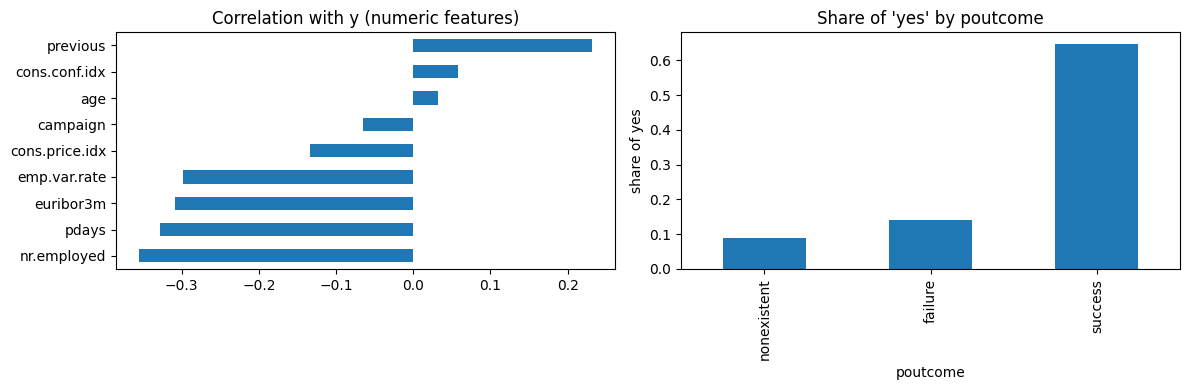

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

corr.plot.barh(ax=ax[0])
ax[0].set_title("Correlation with y (numeric features)")

r = y.groupby(X["poutcome"]).mean().sort_values()
r.plot.bar(ax=ax[1])
ax[1].set_title("Share of 'yes' by poutcome")
ax[1].set_ylabel("share of yes")

plt.tight_layout()
plt.show()

In [7]:
((X["housing"] == "unknown") & (X["loan"] == "unknown")).sum()

np.int64(794)

## Stage 2 · Understanding the data

The training set has 32 940 rows and 3 711 of them are yes,which is 11.3 %.So the classes are imbalanced. A classifier that always says no gets 88.7 % accuracy but does not find any buyer,so accuracy is misleading on these data.

There are no real NaN values in the features (I counted 0),but missing values are hidden in two ways.The first way is the word unknown in the categorical columns.It appears 6 871 times in default (20.9 %),1 401 times in education (4.3 %),794 times in housing and 794 times in loan (2.4 % each),275 times in job (0.8 %) and 64 times in marital (0.2 %).The second way is the number 999 in pdays.It appears in 31 694 rows which is 96.2 % of the data.This is not a real number of days,it means that the client was not contacted before.

About the order of the rows: they look shuffled and not sorted by time.In the first rows the months jump around (may, aug, aug, may, jun).I also cut id into 10 equal parts and the share of yes stayed almost the same in all parts,between 0.105 and 0.118 and the mean euribor3m stayed between 3.57 and 3.67.So the order of id does not carry information about time and my random split does not break any visible order.

Now about the features that are related to the answer.Among the numeric features,nr.employed has correlation -0.356 with y,pdays -0.328, euribor3m -0.308, emp.var.rate -0.299 and previous +0.232,while age is almost not related (+0.032).The correlation of pdays is mostly caused by the value 999,which means that the client was not contacted before.The feature poutcome is very strong: if the previous campaign was a success,64.8 % of the clients say yes (1 130 clients) and if there was no previous campaign (nonexistent),only 8.8 % say yes (28 446 clients).The share of yes also depends on the month: it is 6.4 % in May (10 942 rows) and 51.2 % in March,but March has only 457 rows,so this number is not very stable. For job,students (30.5 %) and retired people (25.0 %) say yes much more often than blue-collar workers (7.0 %).

From this I decided to keep unknown as its own category and to make a flag from pdays instead of using 999 as a number.In Stage 4 I check this by cross-validation.

# Stage 3 · Design the validation

In [8]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print("dev:", X_dev.shape, "| доля yes:", round(y_dev.mean(), 4))
print("hold-out:", X_hold.shape, "| доля yes:", round(y_hold.mean(), 4))

dev: (26352, 19) | доля yes: 0.1127
hold-out: (6588, 19) | доля yes: 0.1126


## Stage 3

- I put 20 % of train.csv aside as my own hold-out (6 588 rows, X_hold, y_hold). I will not touch it until the final evaluation (Stage 7).
- The other 80 % (26 352 rows, X_dev) is used for comparing and tuning models by cross-validation.
- The share of "yes" is almost the same in both parts (0.1127 in dev, 0.1126 in hold-out), so the stratified split worked.
- I use StratifiedKFold with 5 folds, shuffle and random_state = SEED. Stratified, because only 11 % of clients are "yes", and I want the same share in every fold.
- The spread between folds (std of the metric) will be used later: if two models differ by less than this spread, I will not call one of them better.

# Stage 4 · Preprocess inside a pipeline 

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, Binarizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

cat_cols = X_dev.select_dtypes("object").columns.tolist()
num_cols = [c for c in X_dev.select_dtypes("number").columns if c != "pdays"]

def make_pipe(pdays_mode, model):
    if pdays_mode == "raw":
        pdays_step = StandardScaler()
    else:
        pdays_step = Binarizer(threshold=998)
    prep = ColumnTransformer([
        ("num", StandardScaler(), num_cols),
        ("pdays", pdays_step, ["pdays"]),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    return Pipeline([("prep", prep), ("model", model)])

for mode in ["raw", "flag"]:
    pipe = make_pipe(mode, LogisticRegression(max_iter=1000))
    scores = cross_val_score(pipe, X_dev, y_dev, cv=cv, scoring="roc_auc")
    print(f"pdays = {mode:5s} | ROC-AUC per fold: {scores.round(4)} | "
          f"mean {scores.mean():.4f} ± {scores.std():.4f}")

pdays = raw   | ROC-AUC per fold: [0.7976 0.7994 0.7947 0.7891 0.7932] | mean 0.7948 ± 0.0036
pdays = flag  | ROC-AUC per fold: [0.7978 0.7993 0.7948 0.7893 0.7922] | mean 0.7947 ± 0.0036


## Stage 4 · Preprocessing inside a pipeline

In this stage I built one sklearn Pipeline that does all the preprocessing and then fits the model.Numeric columns are scaled with StandardScaler.Categorical columns are encoded with OneHotEncoder and I set handle_unknown to ignore so that a new category in the test data does not break the model.I kept the value unknown as a separate category,because in some columns there are many of them (about 21 % in default) and I think this can also carry information about the client.

I put every step that learns something from the data inside the pipeline and gave the whole pipeline to cross_val_score.Because of this,in every fold the scaler and the encoder are fitted again only on the training part of that fold and then they are just applied to the validation part.So the validation fold never changes the means,the standard deviations or the list of categories.I also checked it directly: the mean of age computed on the training part of one fold is different from the mean on the whole development set,so the scaler really sees only its own training data.

For pdays I compared two options.The value 999 means that the client was not contacted before and it is 96 % of all rows so it is not a real number of days.In the first option I left pdays as a number,in the second I made a flag "not contacted before".I used logistic regression,5-fold stratified cross-validation and ROC-AUC.The raw number gave 0.7948 with std 0.0036 and the flag gave 0.7947 with std 0.0036.The difference is 0.0001 and the spread between the folds is 0.0036,which is about 40 times bigger.So the difference is inside the noise and I can not say that one option is better.I kept the flag only because it is easier to explain and it does not depend on the magic number 999,not because it has a higher score.

The first step of the pipeline is a ColumnTransformer that takes columns by their names,so the saved model can take the raw columns of test.csv (without id) and no manual step is needed before it.I checked that the columns of test.csv are the same as the columns of my training features.

In [10]:
tr_idx, va_idx = next(cv.split(X_dev, y_dev))
sc = StandardScaler().fit(X_dev.iloc[tr_idx][["age"]])
print("mean(age) из train-фолда:", round(float(sc.mean_[0]), 4))
print("mean(age) из всего X_dev:", round(float(X_dev["age"].mean()), 4))
print("Они разные, значит validation-фолд не влияет на scaler.")
print()

pipe_flag = make_pipe("flag", LogisticRegression(max_iter=1000))
pipe_flag.fit(X_dev, y_dev)
test_raw = test.drop(columns=["id"])
print("Колонки test совпадают с X:", list(test_raw.columns) == list(X_dev.columns))
print(pipe_flag.predict_proba(test_raw)[:3, 1].round(3))

mean(age) из train-фолда: 40.0075
mean(age) из всего X_dev: 40.0233
Они разные, значит validation-фолд не влияет на scaler.

Колонки test совпадают с X: True
[0.07 0.03 0.05]


# Stage 5 · Baselines 

In [11]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_validate

scoring = {"accuracy": "accuracy", "roc_auc": "roc_auc", "avg_precision": "average_precision"}

baselines = {
    "majority class": Pipeline([("model", DummyClassifier(strategy="most_frequent"))]),
    "logistic regression": make_pipe("flag", LogisticRegression(max_iter=1000)),
}

for name, model in baselines.items():
    res = cross_validate(model, X_dev, y_dev, cv=cv, scoring=scoring)
    print(name)
    for m in scoring:
        s = res[f"test_{m}"]
        print(f"  {m:14s} {s.mean():.4f} ± {s.std():.4f}")

majority class
  accuracy       0.8873 ± 0.0001
  roc_auc        0.5000 ± 0.0000
  avg_precision  0.1127 ± 0.0001
logistic regression
  accuracy       0.9002 ± 0.0033
  roc_auc        0.7947 ± 0.0036
  avg_precision  0.4610 ± 0.0165


## Stage 5 · Baselines

I made two baselines and ran them on the same 5 stratified folds as everything else,using only the development part.The first one is a majority class classifier,which always answers no.The second one is a simple logistic regression inside the same pipeline from Stage 4.I report the mean and the standard deviation over the folds.

The majority class classifier gets accuracy 0.8873,ROC-AUC 0.5000 and average precision 0.1127.The logistic regression gets accuracy 0.9002,ROC-AUC 0.7947 with std 0.0036 and average precision 0.4610 with std 0.0165.By accuracy the two models are almost the same: the difference is only about 1.3 points and the model that finds nobody already gets 88.7 %.But by the ranking metrics the difference is big.ROC-AUC goes from 0.5 (random order) to 0.79 and average precision goes from 0.113 to 0.461,which is about 4 times more.So accuracy is misleading on these data and I will not use it to choose a model.

These two results are the bar for all the next models.A model is useful only if it is clearly better than logistic regression,which means better by more than the spread between the folds: about 0.004 for ROC-AUC and about 0.017 for average precision.If the difference is smaller than that,I will say that it is inside the noise.

# Stage 6 · Compare models and tune 

In [12]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision"}

models = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

results = {}
for name, model in models.items():
    pipe = make_pipe("flag", model)
    res = cross_validate(pipe, X_dev, y_dev, cv=cv, scoring=scoring)
    results[name] = res
    print(name)
    for m in scoring:
        s = res[f"test_{m}"]
        print(f"  {m:14s} {s.mean():.4f} ± {s.std():.4f}   per fold: {s.round(3)}")

logistic regression
  roc_auc        0.7947 ± 0.0036   per fold: [0.798 0.799 0.795 0.789 0.792]
  avg_precision  0.4610 ± 0.0165   per fold: [0.475 0.47  0.453 0.432 0.475]
random forest
  roc_auc        0.7709 ± 0.0025   per fold: [0.774 0.767 0.772 0.772 0.768]
  avg_precision  0.4125 ± 0.0125   per fold: [0.423 0.409 0.412 0.392 0.427]
KNN (k=5)
  roc_auc        0.7265 ± 0.0056   per fold: [0.721 0.735 0.728 0.729 0.72 ]
  avg_precision  0.3230 ± 0.0117   per fold: [0.316 0.334 0.335 0.304 0.326]


In [13]:
from sklearn.model_selection import GridSearchCV

search_spaces = {
    "logistic regression": (LogisticRegression(max_iter=1000),
                            {"model__C": [0.01, 0.1, 1, 10]}),
    "random forest": (RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1),
                      {"model__max_depth": [6, 12],
                       "model__min_samples_leaf": [5, 20, 50]}),
    "KNN": (KNeighborsClassifier(),
            {"model__n_neighbors": [15, 50, 100]}),
}

scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision"}
tuned = {}

for name, (model, grid) in search_spaces.items():
    gs = GridSearchCV(make_pipe("flag", model), grid, cv=cv,
                      scoring=scoring, refit="roc_auc", n_jobs=1)
    gs.fit(X_dev, y_dev)
    tuned[name] = gs
    i = gs.best_index_
    print(name)
    print("  best params:", gs.best_params_)
    print(f"  roc_auc        {gs.cv_results_['mean_test_roc_auc'][i]:.4f} ± {gs.cv_results_['std_test_roc_auc'][i]:.4f}")
    print(f"  avg_precision  {gs.cv_results_['mean_test_avg_precision'][i]:.4f} ± {gs.cv_results_['std_test_avg_precision'][i]:.4f}")

logistic regression
  best params: {'model__C': 1}
  roc_auc        0.7947 ± 0.0036
  avg_precision  0.4610 ± 0.0165
random forest
  best params: {'model__max_depth': 12, 'model__min_samples_leaf': 5}
  roc_auc        0.8025 ± 0.0020
  avg_precision  0.4739 ± 0.0234
KNN
  best params: {'model__n_neighbors': 100}
  roc_auc        0.7887 ± 0.0058
  avg_precision  0.4344 ± 0.0272


In [15]:
configs = {
    "LR, no weights":       LogisticRegression(max_iter=1000, C=1),
    "LR, balanced":         LogisticRegression(max_iter=1000, C=1, class_weight="balanced"),
    "RF, no weights":       RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                   random_state=SEED, n_jobs=-1),
    "RF, balanced":         RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=5,
                                                   class_weight="balanced", random_state=SEED, n_jobs=-1),
}

scoring = {"roc_auc": "roc_auc", "avg_precision": "average_precision"}
imb_results = {}

for name, model in configs.items():
    res = cross_validate(make_pipe("flag", model), X_dev, y_dev, cv=cv, scoring=scoring)
    imb_results[name] = res
    print(name)
    for m in scoring:
        s = res[f"test_{m}"]
        print(f"  {m:14s} {s.mean():.4f} ± {s.std():.4f}   per fold: {s.round(3)}")

LR, no weights
  roc_auc        0.7947 ± 0.0036   per fold: [0.798 0.799 0.795 0.789 0.792]
  avg_precision  0.4610 ± 0.0165   per fold: [0.475 0.47  0.453 0.432 0.475]
LR, balanced
  roc_auc        0.7957 ± 0.0049   per fold: [0.801 0.802 0.793 0.789 0.794]
  avg_precision  0.4561 ± 0.0172   per fold: [0.471 0.464 0.447 0.427 0.472]
RF, no weights
  roc_auc        0.8025 ± 0.0020   per fold: [0.804 0.806 0.803 0.8   0.801]
  avg_precision  0.4739 ± 0.0234   per fold: [0.481 0.481 0.462 0.437 0.508]
RF, balanced
  roc_auc        0.8020 ± 0.0029   per fold: [0.804 0.807 0.8   0.8   0.799]
  avg_precision  0.4691 ± 0.0182   per fold: [0.474 0.481 0.453 0.444 0.494]
